In [4]:
from sqlalchemy import text
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from scipy.stats import mannwhitneyu, spearmanr

sns.set_theme(style="whitegrid")

In [6]:
schema = os.getenv("DB_SCHEMA", "s_atikesanli")

print("Using database schema:", schema)

Using database schema: s_atikesanli


In [8]:
# Load environment variables
load_dotenv()

# Define schema
schema = os.getenv("DB_SCHEMA", "s_atikesanli")

# Create database connection
connection_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME")
)

engine = create_engine(
    connection_url,
    connect_args={
        "options": "-c default_transaction_read_only=on"
    }
)

# Test connection
with engine.connect() as connection:
    database_name = connection.execute(
        text("SELECT current_database()")
    ).scalar()

print("Connection successful!")
print("Database:", database_name)
print("Schema:", schema)

Connection successful!
Database: nf_da_onl_en_200726
Schema: s_atikesanli


In [9]:
# Retrieve delivery duration and review score for RQ2
rq2_query = text(f"""
    SELECT
        order_id,
        delivery_duration_days,
        average_review_score
    FROM {schema}.int_order_customer_satisfaction
    WHERE order_status = 'delivered'
      AND chronology_status = 'Valid chronology'
      AND delivery_performance IN ('Late', 'On time or early')
      AND delivery_duration_days IS NOT NULL
      AND average_review_score IS NOT NULL
""")

with engine.connect() as connection:
    rq2_df = pd.read_sql_query(rq2_query, connection)

print("RQ2 dataset dimensions:", rq2_df.shape)
display(rq2_df.head())

RQ2 dataset dimensions: (95178, 3)


,order_id,delivery_duration_days,average_review_score
0,9b6c23f7e50fe64b97022b8c0d3602a6,10.03,5.0
1,a7ba0112ae1019055442b330ee484e67,5.04,5.0
2,f6e13cf914f6c5fdcbd6100c8bcdb389,4.99,5.0
3,2889a938b438bbaf4701f63a2545bb3b,7.39,5.0
4,ed273cdf7e2668c17d6cb199ad52d7c4,10.17,5.0


In [10]:
print("DATA QUALITY CHECK – RQ2")
print("-" * 40)

print("\nDataset information:")
rq2_df.info()

print("\nMissing values:")
display(rq2_df.isnull().sum())

print("\nDuplicate order IDs:", rq2_df["order_id"].duplicated().sum())

print("\nDelivery duration summary:")
display(rq2_df["delivery_duration_days"].describe().to_frame())

print("\nReview score summary:")
display(rq2_df["average_review_score"].describe().to_frame())

print(
    "\nOrders with zero or negative delivery duration:",
    (rq2_df["delivery_duration_days"] <= 0).sum()
)

DATA QUALITY CHECK – RQ2
----------------------------------------

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 95178 entries, 0 to 95177
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_id                95178 non-null  str    
 1   delivery_duration_days  95178 non-null  float64
 2   average_review_score    95178 non-null  float64
dtypes: float64(2), str(1)
memory usage: 2.2 MB

Missing values:


order_id                  0
delivery_duration_days    0
average_review_score      0
dtype: int64


Duplicate order IDs: 0

Delivery duration summary:


,delivery_duration_days
count,95178.000000
mean,12.519681
std,9.465902
min,0.530000
25%,6.760000
50%,10.210000
75%,15.660000
max,208.350000



Review score summary:


,average_review_score
count,95178.000000
mean,4.158083
std,1.282337
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000



Orders with zero or negative delivery duration: 0


In [11]:
from scipy.stats import spearmanr

# Calculate Spearman's rank correlation
rho, p_value = spearmanr(
    rq2_df["delivery_duration_days"],
    rq2_df["average_review_score"]
)

print("SPEARMAN RANK CORRELATION – RQ2")
print("-" * 45)

print(f"Sample size: {len(rq2_df):,}")
print(f"Spearman correlation (rho): {rho:.4f}")
print(f"P-value: {p_value:.10g}")

if p_value < 0.05:
    print("\nResult: Statistically significant relationship.")
else:
    print("\nResult: No statistically significant relationship.")

if rho < 0:
    print("Direction: Negative – longer delivery times tend to")
    print("be associated with lower customer review scores.")
elif rho > 0:
    print("Direction: Positive – longer delivery times tend to")
    print("be associated with higher customer review scores.")
else:
    print("Direction: No observed monotonic association.")

SPEARMAN RANK CORRELATION – RQ2
---------------------------------------------
Sample size: 95,178
Spearman correlation (rho): -0.2353
P-value: 0

Result: Statistically significant relationship.
Direction: Negative – longer delivery times tend to
be associated with lower customer review scores.


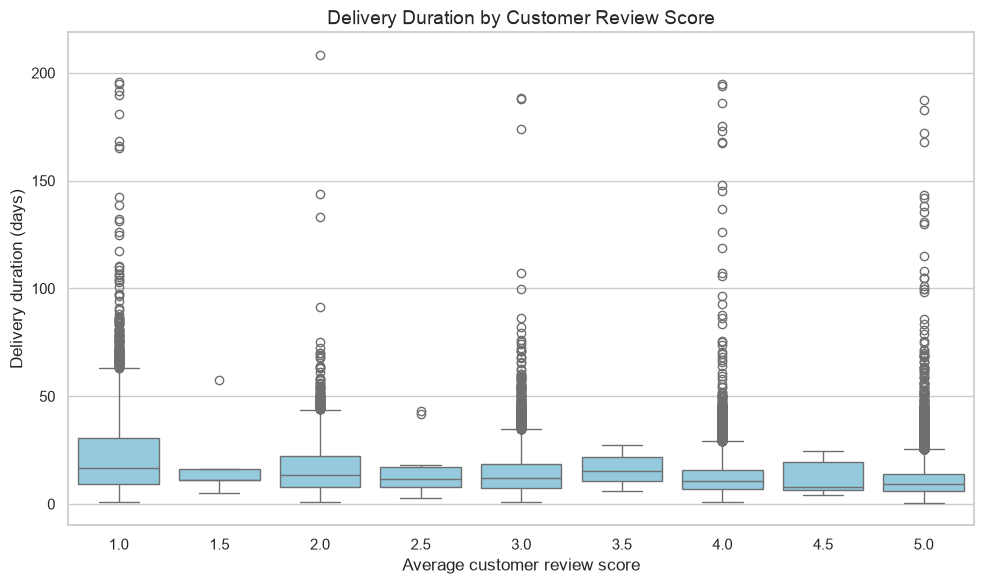

In [12]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=rq2_df,
    x="average_review_score",
    y="delivery_duration_days",
    color="skyblue"
)

plt.title(
    "Delivery Duration by Customer Review Score",
    fontsize=14
)
plt.xlabel("Average customer review score")
plt.ylabel("Delivery duration (days)")
plt.tight_layout()

plt.savefig(
    "../figures/rq2_duration_by_review_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
rq2_summary = (
    rq2_df.groupby("average_review_score")
    ["delivery_duration_days"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

rq2_summary.index.name = "Customer review score"

display(rq2_summary)

,count,mean,median,std
Customer review score,,,,
1.0,9223,21.39,16.87,16.12
1.5,5,20.15,10.99,21.33
2.0,2894,16.68,13.28,12.49
2.5,12,16.15,11.59,13.15
3.0,7854,14.26,12.06,9.93
3.5,11,15.91,15.38,7.70
4.0,18777,12.31,10.79,8.29
4.5,18,12.21,8.09,6.95
5.0,56384,10.68,9.23,6.82


## RQ2 – Results and interpretation

Spearman's rank correlation was used to investigate the relationship between delivery duration and customer review scores. The analysis included 95,178 delivered orders with valid chronology and available review scores.

The results indicated a statistically significant negative association between delivery duration and customer review scores (Spearman's rho = −0.2353, p < .001). This suggests that orders taking longer to reach customers tended to receive lower review scores.

The descriptive analysis supports this finding. Orders receiving a review score of 1 had an average delivery duration of 21.39 days, compared with 10.68 days for orders receiving a score of 5. The median delivery duration across the full sample was 10.21 days.

The null hypothesis is therefore rejected, and the alternative hypothesis is supported.

Although the association is statistically significant, its strength is relatively weak to moderate. This indicates that delivery duration is one factor associated with customer satisfaction, while other aspects of the shopping and delivery experience may also influence customer reviews.

The findings demonstrate an association rather than a causal relationship.

In [14]:
# Inspect the 15 longest delivery durations
longest_deliveries = (
    rq2_df.nlargest(15, "delivery_duration_days")
    [["order_id", "delivery_duration_days", "average_review_score"]]
    .reset_index(drop=True)
)

display(longest_deliveries)

# Count unusually long deliveries
print("\nLONG DELIVERY DURATION COUNTS")
print("-" * 40)

for days in [30, 60, 90, 120]:
    count = (rq2_df["delivery_duration_days"] > days).sum()
    percentage = count / len(rq2_df) * 100

    print(f"More than {days} days: {count:,} ({percentage:.2f}%)")

,order_id,delivery_duration_days,average_review_score
0,1b3190b2dfa9d789e1f14c05b647a14a,208.35,2.0
1,440d0d17af552815d15a9e41abe49359,195.63,1.0
2,2fb597c2f772eca01b1f5c561bf6cc7b,194.85,4.0
3,285ab9426d6982034523a855f55a885e,194.63,1.0
4,0f4519c5f1c541ddec9f21b3bddd533a,194.05,4.0
5,47b40429ed8cce3aee9199792275433f,191.46,1.0
6,2fe324febf907e3ea3f2aa9650869fa5,189.86,1.0
7,2d7561026d542c8dbd8f0daeadf67a43,188.13,3.0
8,c27815f7e3dd0b926b58552628481575,187.74,3.0
9,437222e3fd1b07396f1d9ba8c15fba59,187.20,5.0



LONG DELIVERY DURATION COUNTS
----------------------------------------
More than 30 days: 4,398 (4.62%)
More than 60 days: 290 (0.30%)
More than 90 days: 73 (0.08%)
More than 120 days: 41 (0.04%)


In [15]:
from scipy.stats import spearmanr

duration_limits = [None, 60, 30]

for limit in duration_limits:
    if limit is None:
        subset = rq2_df.copy()
        label = "All orders"
    else:
        subset = rq2_df[
            rq2_df["delivery_duration_days"] <= limit
        ].copy()
        label = f"Orders up to {limit} days"

    rho, p_value = spearmanr(
        subset["delivery_duration_days"],
        subset["average_review_score"]
    )

    print(f"\n{label}")
    print(f"Sample size: {len(subset):,}")
    print(f"Spearman correlation: {rho:.4f}")
    print(f"P-value: {p_value:.3e}")


All orders
Sample size: 95,178
Spearman correlation: -0.2353
P-value: 0.000e+00

Orders up to 60 days
Sample size: 94,888
Spearman correlation: -0.2306
P-value: 0.000e+00

Orders up to 30 days
Sample size: 90,780
Spearman correlation: -0.1595
P-value: 0.000e+00


### Sensitivity analysis

To assess whether exceptionally long delivery durations influenced the observed relationship between delivery time and customer satisfaction, a sensitivity analysis was conducted using two restricted datasets.

The primary analysis, including all 95,178 eligible orders, identified a negative Spearman correlation between delivery duration and average review score (ρ = −0.2353, p < .001). When orders with delivery durations exceeding 60 days were excluded, the correlation remained similar (N = 94,888, ρ = −0.2306, p < .001).

However, excluding orders taking more than 30 days to deliver resulted in a weaker negative correlation (N = 90,780, ρ = −0.1595, p < .001).

These findings indicate that exceptionally long delivery durations contribute to the strength of the observed association. Nevertheless, the negative relationship remains present even after excluding these orders. Therefore, the main finding is not solely driven by extreme delivery durations. All eligible orders were retained in the primary analysis to avoid excluding potentially genuine delivery experiences.